# Weekly project 6
Today we will continue work from monday.
We will follow the style of last week.

Weekly project:
- You will need to implement your own k-means algorithm. You are not allowed to use the implementation in `sklearn`.
- It should be able to cluster each of the different figures.
- Extend your k-means so it finds the optimal amount of clusters.
  
## Challenge
- Implement the mean shift clustering algorithm


In [2]:
import numpy as np
import open3d as o3d
import copy
import matplotlib.pyplot as plt

def draw_labels_on_model(pcl, labels):
    cmap = plt.get_cmap("tab20")
    pcl_temp = copy.deepcopy(pcl)
    max_label = labels.max()
    colors = cmap(labels / (max_label if max_label > 0 else 1))
    colors[labels < 0] = 0
    pcl_temp.colors = o3d.utility.Vector3dVector(colors[:, :3])
    o3d.visualization.draw_geometries([pcl_temp])

d = 4
mesh = o3d.geometry.TriangleMesh.create_tetrahedron().translate((-d, 0, 0))
mesh += o3d.geometry.TriangleMesh.create_octahedron().translate((0, 0, 0))
mesh += o3d.geometry.TriangleMesh.create_icosahedron().translate((d, 0, 0))
mesh += o3d.geometry.TriangleMesh.create_torus().translate((-d, -d, 0))
mesh += o3d.geometry.TriangleMesh.create_mobius(twists=1).translate((0, -d, 0))
mesh += o3d.geometry.TriangleMesh.create_mobius(twists=2).translate((d, -d, 0))

## apply k means on this
point_cloud = mesh.sample_points_uniformly(int(1e3))


## K-means implementation

K-means splits the points into `k` groups by alternating between two steps until the groups stop changing.

The function keeps track of two arrays:
- `centers`: a `(k, 3)` array with one 3D point per cluster.
- `labels`: an `(N,)` array of integers, one per point, giving the index of the cluster that point belongs to.

### 1. Initialisation
The point cloud is converted to an `(N, 3)` numpy array with `np.asarray(pcl.points)`. We pick `k` distinct points at random (`np.random.choice(..., replace=False)`) and use them as the starting centers. Picking existing points guarantees every center starts inside the data.

### 2. Assignment step
With the centers fixed, each point gets the label of its nearest center. For each point we compute the Euclidean distance to all `k` centers with `math.dist` and take the index of the smallest one (`np.argmin`).

### 3. Update step
With the labels fixed, each center moves to the mean of the points assigned to it:

$$\mu_j = \frac{1}{|C_j|} \sum_{x_i \in C_j} x_i$$

where $C_j$ is the set of points with label $j$. If a cluster ends up with no points, its center stays where it was. Otherwise the mean would be undefined (NaN).

### 4. Convergence check
We measure how far each center moved in this iteration (`np.linalg.norm(new_centers - centers, axis=1)`). If even the center that moved most moved less than `1e-4`, the labels and centers have settled, so we stop. Otherwise we repeat steps 2–3. `max_iterations` is a safety limit in case it never settles.

### Return value
The function returns `labels` (used to colour the point cloud), `centers`, and `points` (the point cloud as an array). `centers` and `points` are needed later to compute the distortion when choosing the best `k`.

`draw_labels_on_model` is the same helper as above, plus a print of how many clusters were found.

In [3]:
import math


def kmeans(pcl, n_clusters, max_iterations):
    """Cluster a point cloud into n_clusters groups using k-means.

    Starts from randomly chosen points as centers, then alternates between
    assigning each point to its nearest center and moving each center to the
    mean of its assigned points, until the centers stop moving.

    Args:
        pcl (o3d.geometry.PointCloud): point cloud to cluster.
        n_clusters (int): number of clusters k.
        max_iterations (int): maximum number of assign/update iterations.

    Returns:
        labels (np.ndarray, shape (N,)): cluster index for each point.
        centers (np.ndarray, shape (k, 3)): final cluster centers.
        points (np.ndarray, shape (N, 3)): the point cloud as an array.
    """
    #Turn pcl into an array
    points = np.asarray(pcl.points)

    N = points.shape[0]

    #Choose random centers
    idx = np.random.choice(N, n_clusters, replace=False)  # k distinct indices
    centers = points[idx].copy()


    for it in range(max_iterations):

        labels = np.zeros(N, dtype=int)
        for i in range(N):
            d = [math.dist(points[i], c) for c in centers]
            labels[i] = np.argmin(d)


        #Update centers
        new_centers = centers.copy()
        for j in range(n_clusters):
            members = []
            for i in range(N):
                if labels[i] == j:
                    members.append(points[i])
            if len(members) > 0:
                new_centers[j] = np.mean(members, axis=0)

        #Convergence check
        shift = np.linalg.norm(new_centers - centers, axis=1)
        centers = new_centers
        if shift.max() < 1e-4:
            break


    return labels, centers, points


def draw_labels_on_model(pcl,labels):
    cmap = plt.get_cmap("tab20")
    pcl_temp = copy.deepcopy(pcl)
    max_label = labels.max()
    print("%s has %d clusters" % ("pointcloud", max_label + 1))
    colors = cmap(labels / (max_label if max_label > 0 else 1))
    colors[labels < 0] = 0
    pcl_temp.colors = o3d.utility.Vector3dVector(colors[:, :3])
    o3d.visualization.draw_geometries([pcl_temp])

## Running k-means on the shapes

The scene has six separate shapes (tetrahedron, octahedron, icosahedron, torus and two Möbius strips), so we first run k-means with `k = 6` and up to 50 iterations. The result is shown with one colour per cluster.

In [4]:
labels, centers, points = kmeans(point_cloud, 6, 50)

draw_labels_on_model(point_cloud, labels)

pointcloud has 6 clusters


A good run: each shape gets its own cluster.

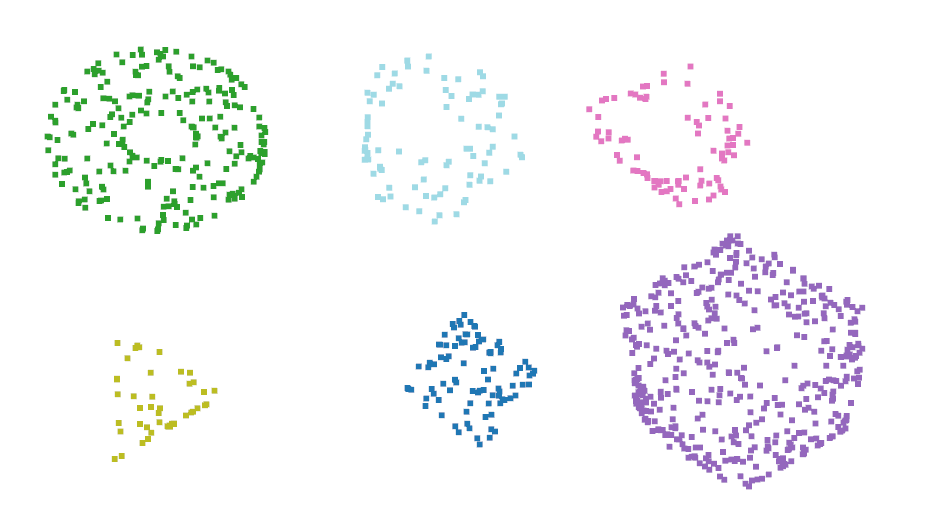

### Why the result varies between runs

K-means only finds a *local* optimum, and which one depends on the random starting centers. If two starting centers land on the same shape and none on another, the algorithm converges with that shape split in two and two neighbouring shapes merged. Each update only moves a center to the mean of its nearby points, so nothing pulls a center across the gap to the shape that has none.

In the bad run below, the tetrahedron and octahedron share one cluster (purple) while the icosahedron is split in two (green and pink). In testing, only about 1 in 4 single runs with `k = 6` separated all six shapes. The icosahedron makes this worse: `sample_points_uniformly` samples by surface area, so the large icosahedron gets about 40% of all points and readily attracts two centers.

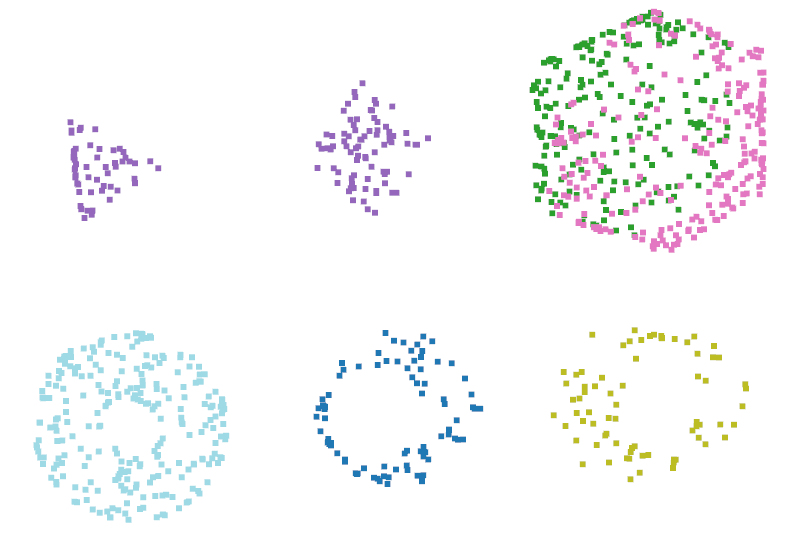

The fix is to **run k-means several times and keep the run with the lowest distortion** (defined below). A wrong clustering always has a higher distortion than the correct one: about 1970 or more versus about 1750 in testing. So if at least one of the runs is correct, it gets picked.

## Choosing the optimal k

To find the number of clusters automatically, `optimal_kmeans` runs k-means for every `k` in a range. It keeps the best of `n_runs` restarts for each `k`, then uses two measures.

### Distortion and the elbow plot
The distortion is the total squared distance from each point to the center of its own cluster:

$$J = \sum_{i=1}^{N} \lVert x_i - \mu_{\text{label}(i)} \rVert^2$$

In code this is `np.sum((points - centers[labels]) ** 2)`. `centers[labels]` gives each point its own cluster center. The distortion always decreases as `k` grows, so the usual *elbow method* plots it against `k` and looks for the point where adding another cluster stops helping much. The distortion is also how we choose the best of the restarts.

### Gap between clusters
What actually makes the six shapes separate objects is the empty space between them. For each `k`, we find the smallest distance between two points that lie in *different* clusters:
- If every cluster is a whole shape, or a group of whole shapes, that gap is large (about 1.2 here).
- As soon as k-means has to cut through a shape, the gap collapses to roughly the spacing between neighbouring points (about 0.1–0.2).

A gap counts as real if it's larger than the largest nearest-neighbour distance in the cloud. That threshold comes from the data itself, so no tuning is needed. **The optimal `k` is the largest `k` whose clusters are still separated by a real gap.** The pairwise distance matrix `D` is computed once and reused for every `k`.

In [5]:
#Extended k-means finding optimal ammount of clusters
def optimal_kmeans(pcl, ks, max_iterations, n_runs=5):
    points = np.asarray(pcl.points)
    D = np.linalg.norm(points[:, None] - points[None], axis=2)   # all pairwise distances
    np.fill_diagonal(D, np.inf)
    threshold = D.min(axis=1).max()   # largest nearest-neighbour distance

    best_k = 1
    best_labels = np.zeros(len(points), dtype=int)
    distortions = []
    for k in ks:
        # best of several runs, so one bad start doesn't ruin this k
        runs = [kmeans(pcl, k, max_iterations) for _ in range(n_runs)]
        labels, centers, _ = min(runs, key=lambda r: np.sum((points - r[1][r[0]]) ** 2))
        distortions.append(np.sum((points - centers[labels]) ** 2))

        if k < 2:
            continue   # one cluster has no "between clusters" gap to measure

        gap = D[labels[:, None] != labels[None]].min()   # closest pair in different clusters
        if gap > threshold:
            best_k = k
            best_labels = labels

    # Elbow plot
    plt.plot(list(ks), distortions, "o-")
    plt.axvline(best_k, color="gray", linestyle="--", label="chosen k = %d" % best_k)
    plt.xlabel("k"); plt.ylabel("distortion")
    plt.legend()
    plt.show()

    return best_k, best_labels

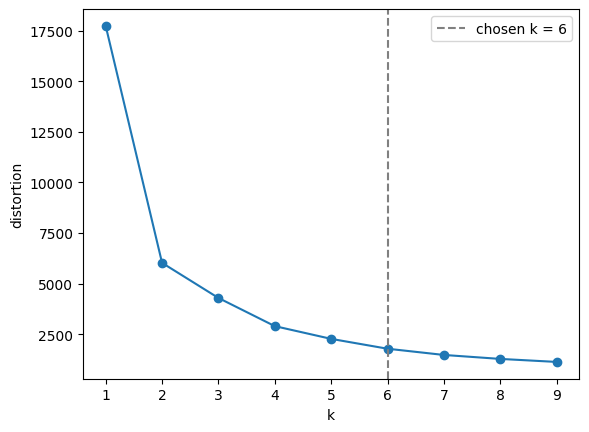

the optimal value for k is: 6
pointcloud has 6 clusters


In [6]:
k, labels = optimal_kmeans(point_cloud, range(1,10), 100)
print("the optimal value for k is: " + str(k))

draw_labels_on_model(point_cloud, labels)

### Reading the elbow plot
On this scene the elbow plot alone is ambiguous. The sharpest bend is at `k = 2`, where the cloud is split roughly into its two rows, and the curve keeps dropping noticeably after `k = 6`. That is because the icosahedron and torus are large and hold many points, so splitting them further still reduces the distortion. Elbow detection on this curve picks 2, and so does the silhouette score. That is why the gap criterion is used to make the decision, with the plot shown for reference.

The final colouring uses the best labels found for the chosen `k`. It doesn't run k-means again, which could land in a bad local optimum.

### Why the optimal k is mostly 6 but sometimes 5
This is the same local-optimum problem as above. `k = 6` only passes the gap test if at least one of the restarts separates all six shapes. Occasionally every restart lands in a bad clustering that cuts through a shape. The gap then collapses, `k = 6` is rejected, and the answer falls back to 5 (two neighbouring shapes merged, but none cut). More restarts or a better initialisation such as k-means++ make this rarer.

# Challenge: Mean shift clustering

While the idea behind mean shift clustering is that have a density maps with peaks, implementing it you actually never have to build the whole density map. Instead you can just climb it directly through the steps described in the slides and it will cluster into the correct attraction basin.
So while the KDE is 

`f_h = 1 / (n*h) * sum(kernel(x, x_i, h))`

and the sum of the densities from all the points make up the density map we never have to build it, we can just do gradient ascent implicitly instead.

## Simpler solution

While we initially attempted the gradient ascent based on the densities, we opted for a simpler loop first that just clips a circle around each point and shifts the mean based on the the equally weighted mean of all points inside this circle. Then we get a good solution without the complexity of doing gradient ascent.


In [ ]:
def mean_shift_clustering(pcl, h, convergence_criteria = 0.02, merge_cluster_dist = 0.5):
    points = np.asarray(pcl.points) # Shape: (n_points, dims)
    n_points = points.shape[0]
    dim = points.shape[1]
    labels = np.zeros(n_points, dtype=int)   # init the labels array

    modes = [] # or "peaks"
    for i in range(len(points)):
        point = points[i]

        # initialize the first center and move it based on the mean of the points in the search window
        old_center = point
        search_window = points[np.linalg.norm(points - old_center, axis=1) <= h] # The search window is made by masking the points
        new_center = search_window.mean(axis=0)

        while np.linalg.norm(new_center - old_center) > convergence_criteria:
            old_center = new_center
            search_window = points[np.linalg.norm(points - old_center, axis=1) <= h]
            new_center = search_window.mean(axis=0)

        modes.append(new_center)

    # merge close centers
    centers = []
    for i, mode in enumerate(modes):
        for k, c in enumerate(centers):
            if np.linalg.norm(mode - c) < merge_cluster_dist:
                labels[i] = k
                break
        else:
            centers.append(mode)
            labels[i] = len(centers) - 1

    return np.array(centers), labels

h = 2 # "bandwidth"

centers, labels = mean_shift_clustering(point_cloud, h)

print("Number of centers: ", len(centers))
draw_labels_on_model(point_cloud, labels)



Number of centers:  6
pointcloud has 6 clusters


## Conclusions on mean shift algorithm


Tweaking the parameters of the mean shift algorithm we found some interesting chnages.

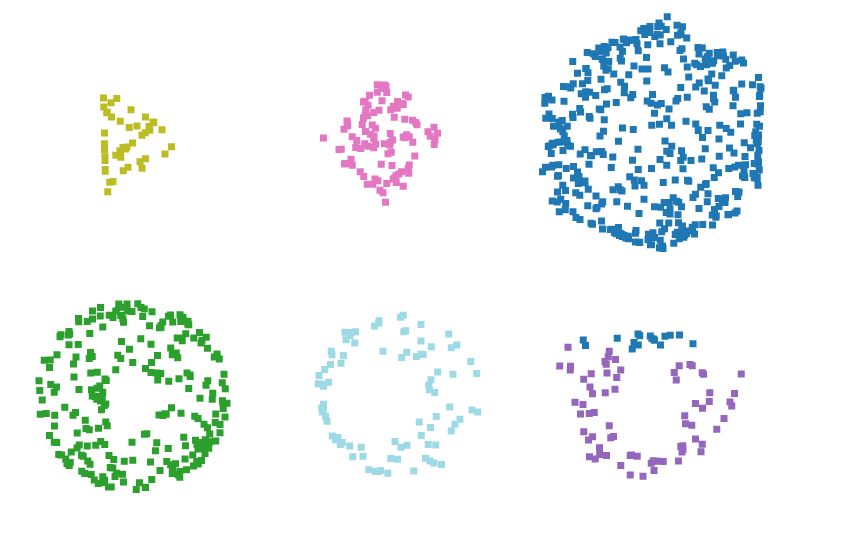

The picture above shows the best cluestering we were able to acheive setting the bandwidth to 2.

As soon as we lowered the bandwidth below 2 the top right sphere would be split into many different clusters. This would make good sense if the radius of the sphere was exactly 2 as a bandwidth of 2 would lead to a huge peak in the middle of the circle where the circle would just about reach all the points whereas if the bandwidth was below 2 it would instead create a lot of smaller peaks around the edges of the sphere.

We see however that some of the points of the bottom right shape is assigned to the blue cluster. This is because the bandwidth of 2 lets them see the points of the sphere above and therefore move towards the sphere center peak/mode. This could be solved either by moving the shapes a bit further apart (this would lead to perfect clustering) or by lowering the bandwidth which would in turn break the clustering of the circle as described above.

**AI disclaimer:** AI was used to assist and polish in writing of explanations, comments, and some helper function suggestions.